# Module 0 — Les fondements des réseaux de neurones

> **Objectif** : comprendre *exactement* ce qui se passe quand un réseau de neurones « apprend ». À la fin de ce module, tu sauras écrire de zéro (en NumPy) un réseau multicouche, sa fonction de perte, sa rétropropagation et son optimiseur, et tu sauras pourquoi chaque brique existe. Ensuite, le même travail en PyTorch tiendra en 20 lignes.

| | |
|---|---|
| **Durée estimée** | 3 à 4 h (lecture + exécution + exercices) |
| **Prérequis** | Python, NumPy de base, dérivées et produit matriciel (niveau licence) |
| **Librairies** | `numpy`, `matplotlib`, et `torch` pour la dernière section |

**Plan**

1. Le problème d'apprentissage en une équation
2. Le neurone artificiel : un hyperplan qui décide
3. Les fonctions d'activation (et pourquoi sans elles tout s'effondre)
4. Les fonctions de perte : d'où elles viennent vraiment
5. La descente de gradient
6. Les optimiseurs modernes : Momentum, RMSProp, Adam
7. La rétropropagation : la règle de la chaîne, industrialisée
8. Un MLP complet en NumPy, de zéro
9. L'initialisation des poids
10. Généralisation et régularisation
11. La même chose en PyTorch
12. Récapitulatif, pièges fréquents, exercices

Chaque section suit la même structure : **💡 Intuition → 📐 Maths → 💻 Code → 📊 Visualisation**.

## 0. Mise en place

Toutes les cellules de ce notebook jusqu'à la section 11 n'utilisent que NumPy et Matplotlib : rien n'est caché derrière une librairie.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Colorblind-safe categorical palette (fixed order) + quiet axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 100,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)
print("numpy", np.__version__)

numpy 2.5.3


## 1. Le problème d'apprentissage en une équation

### 💡 Intuition

Apprendre, pour une machine, c'est **régler des boutons**. Un modèle est une fonction $f_\theta$ avec des paramètres $\theta$ (des milliers, des millions, parfois des milliards de « boutons »). On lui montre des exemples $(x, y)$, on mesure à quel point ses prédictions $\hat y = f_\theta(x)$ sont mauvaises avec une **fonction de perte** $\ell$, et on tourne les boutons dans la direction qui réduit l'erreur. On recommence, encore et encore.

Les quatre ingrédients de *tout* modèle de deep learning, y compris GPT :

| Ingrédient | Question | Exemple NLP |
|---|---|---|
| **Données** | Qu'apprend-on ? | phrases → sentiment |
| **Modèle** $f_\theta$ | Quelle famille de fonctions ? | Transformer |
| **Perte** $\ell$ | Comment mesurer l'erreur ? | entropie croisée |
| **Optimiseur** | Comment régler $\theta$ ? | AdamW |

### 📐 Maths

On cherche les paramètres qui minimisent le **risque empirique**, la perte moyenne sur les $N$ exemples d'entraînement :

$$
\theta^\star = \arg\min_\theta \; \mathcal{L}(\theta) = \arg\min_\theta \; \frac{1}{N}\sum_{i=1}^{N} \ell\big(f_\theta(x_i),\, y_i\big)
$$

Tout le reste de ce module répond à trois questions : *quelle forme donner à $f_\theta$* (sections 2–3), *quel $\ell$ choisir* (section 4), *comment trouver $\theta^\star$* (sections 5–7).

> ⚠️ **Le vrai but n'est pas de minimiser $\mathcal{L}$** : c'est de bien prédire sur des données *jamais vues*. Minimiser la perte d'entraînement n'est qu'un moyen. On y revient en section 10.

## 2. Le neurone artificiel : un hyperplan qui décide

### 💡 Intuition

Un neurone fait deux choses :
1. il calcule une **somme pondérée** de ses entrées (chaque entrée a un poids qui dit « à quel point elle compte ») plus un biais ;
2. il passe ce score dans une **fonction d'activation** non linéaire.

Pense à un recruteur qui note un CV : +3 points par année d'expérience, +5 si diplôme, −2 si le CV fait 6 pages… puis il décide « oui » si le score dépasse un seuil. Les poids, ce sont les points ; le biais, c'est le seuil.

### 📐 Maths

Pour une entrée $x \in \mathbb{R}^d$, des poids $w \in \mathbb{R}^d$ et un biais $b \in \mathbb{R}$ :

$$
z = w^\top x + b = \sum_{j=1}^{d} w_j x_j + b, \qquad a = \sigma(z)
$$

$z$ s'appelle la **pré-activation** (ou *logit*), $a$ l'**activation**. L'ensemble des points où $z = 0$ est un **hyperplan** (une droite en 2D) : le neurone coupe l'espace en deux. $w$ est orthogonal à cet hyperplan et pointe vers la région où $z > 0$ ; $b$ le décale.

Pour traiter un **batch** de $B$ exemples à la fois, on empile les entrées en une matrice $X \in \mathbb{R}^{B\times d}$, et pour $h$ neurones en parallèle on empile les poids en $W \in \mathbb{R}^{d\times h}$ :

$$
Z = XW + b \in \mathbb{R}^{B\times h}
$$

C'est une **couche dense** (*fully connected*, `nn.Linear` en PyTorch). Retiens les formes : on les retrouvera dans la rétropropagation.

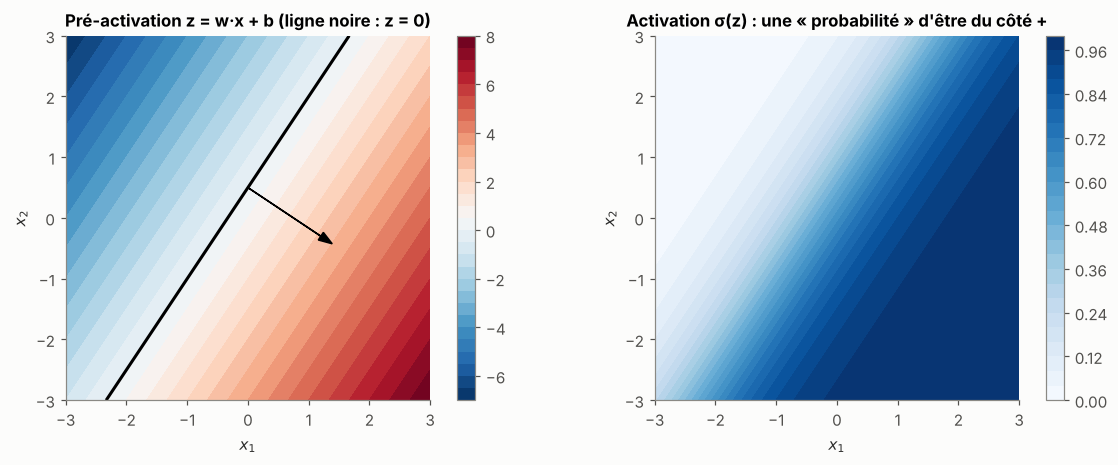

In [2]:
# One neuron in 2D: visualize z = w.x + b and its decision line
w = np.array([1.5, -1.0])
b = 0.5
xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
z = grid @ w + b
a = 1 / (1 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
im = axes[0].contourf(xx, yy, z.reshape(xx.shape), levels=30, cmap="RdBu_r")
axes[0].contour(xx, yy, z.reshape(xx.shape), levels=[0], colors="k", linewidths=2)
axes[0].arrow(0, 0.5, w[0] * 0.8, w[1] * 0.8, head_width=0.15, color="k")  # starts on the line z = 0
axes[0].set_title("Pré-activation z = w·x + b (ligne noire : z = 0)")
plt.colorbar(im, ax=axes[0])
im2 = axes[1].contourf(xx, yy, a.reshape(xx.shape), levels=30, cmap="Blues")
axes[1].set_title("Activation σ(z) : une « probabilité » d'être du côté +")
plt.colorbar(im2, ax=axes[1])
for ax in axes:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal"); ax.grid(False)
plt.tight_layout()
plt.show()

La flèche est le vecteur $w$ : il est perpendiculaire à la frontière et pointe vers les $z$ positifs. **Un seul neurone ne sait tracer qu'une frontière droite.** C'est la limite que les couches cachées vont lever.

## 3. Les fonctions d'activation

### 💡 Intuition : pourquoi a-t-on besoin de non-linéarité ?

Empiler des couches linéaires ne sert **à rien** : une composition de fonctions linéaires reste linéaire. Dix couches linéaires équivalent à une seule. L'activation non linéaire est ce qui permet de « plier » l'espace, couche après couche, jusqu'à rendre séparables des données qui ne l'étaient pas.

### 📐 Maths : la preuve en une ligne

$$
W_2(W_1 x + b_1) + b_2 = \underbrace{(W_2 W_1)}_{W'}\,x + \underbrace{(W_2 b_1 + b_2)}_{b'}
$$

Avec une non-linéarité $\phi$ entre les deux, $W_2\,\phi(W_1x+b_1)+b_2$ ne se simplifie plus. Le **théorème d'approximation universelle** (Cybenko 1989, Hornik 1991) dit même qu'une seule couche cachée assez large, avec une activation non polynomiale, peut approcher n'importe quelle fonction continue sur un compact. En pratique, la profondeur rend cette approximation *beaucoup* plus économe en paramètres.

### Le zoo des activations

| Nom | Formule | Dérivée | Où on la croise |
|---|---|---|---|
| Sigmoïde | $\sigma(z)=\frac{1}{1+e^{-z}}$ | $\sigma(z)(1-\sigma(z))$ | sortie binaire, portes des LSTM |
| Tanh | $\tanh(z)$ | $1-\tanh^2(z)$ | RNN, LSTM |
| ReLU | $\max(0,z)$ | $\mathbb{1}[z>0]$ | MLP, CNN, par défaut |
| Leaky ReLU | $\max(\alpha z, z)$ | $1$ ou $\alpha$ | quand des ReLU « meurent » |
| GELU | $z\,\Phi(z)$ | $\Phi(z)+z\,\varphi(z)$ | **BERT, GPT** |
| SiLU / Swish | $z\,\sigma(z)$ | $\sigma(z)(1+z(1-\sigma(z)))$ | **LLaMA** (via SwiGLU), ESM |

($\Phi$ et $\varphi$ sont la fonction de répartition et la densité de la loi normale standard.)

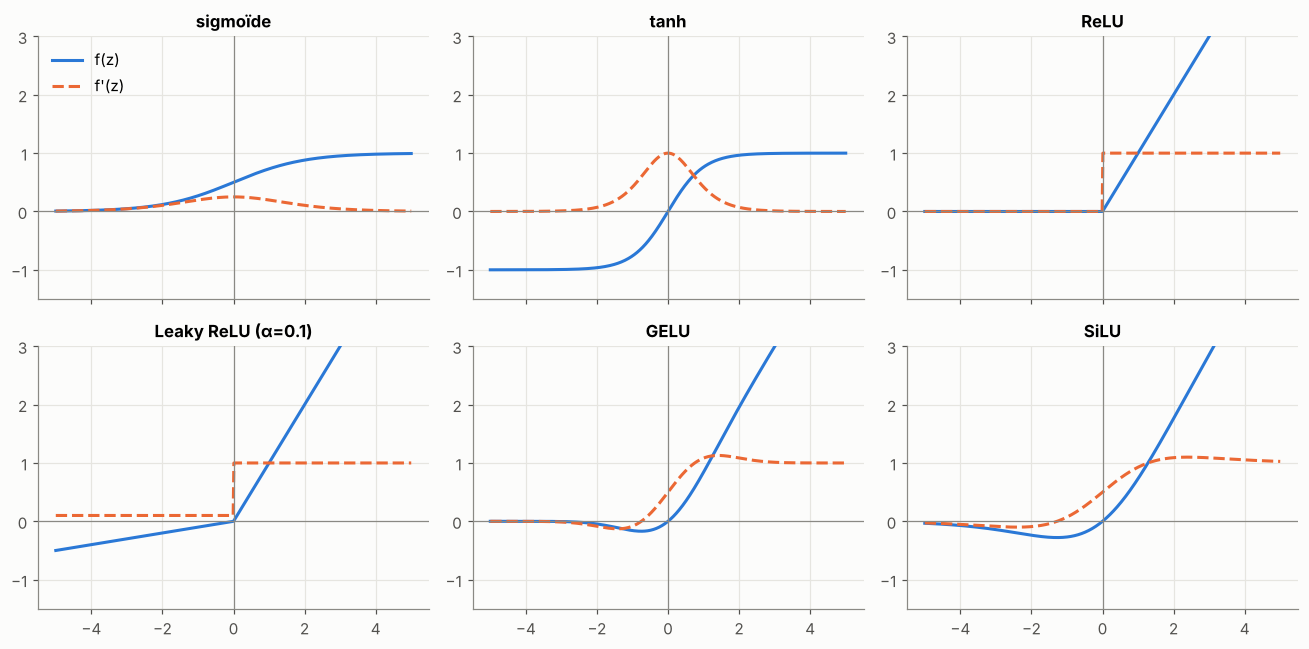

In [3]:
from math import erf, sqrt, pi

z = np.linspace(-5, 5, 500)
sig = lambda z: 1 / (1 + np.exp(-z))
Phi = np.vectorize(lambda t: 0.5 * (1 + erf(t / sqrt(2))))
phi = lambda t: np.exp(-t**2 / 2) / sqrt(2 * pi)

acts = {
    "sigmoïde": (sig(z), sig(z) * (1 - sig(z))),
    "tanh": (np.tanh(z), 1 - np.tanh(z) ** 2),
    "ReLU": (np.maximum(0, z), (z > 0).astype(float)),
    "Leaky ReLU (α=0.1)": (np.where(z > 0, z, 0.1 * z), np.where(z > 0, 1, 0.1)),
    "GELU": (z * Phi(z), Phi(z) + z * phi(z)),
    "SiLU": (z * sig(z), sig(z) * (1 + z * (1 - sig(z)))),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (name, (f, df)) in zip(axes.ravel(), acts.items()):
    ax.plot(z, f, label="f(z)", color=PALETTE[0])
    ax.plot(z, df, label="f'(z)", color=PALETTE[1], linestyle="--")
    ax.axhline(0, color="#8a8984", lw=0.8); ax.axvline(0, color="#8a8984", lw=0.8)
    ax.set_title(name); ax.set_ylim(-1.5, 3)
axes[0, 0].legend(loc="upper left")
plt.tight_layout(); plt.show()

**Ce qu'il faut lire sur ces courbes** (la courbe pointillée, la dérivée, est la plus importante) :

- **Sigmoïde et tanh saturent** : pour $|z|$ grand, leur dérivée est quasi nulle. Or le gradient qui remonte dans le réseau est *multiplié* par cette dérivée à chaque couche → il s'éteint. C'est le **problème du gradient évanescent**. Note aussi que $\sigma'(z) \le 0.25$ : dix sigmoïdes empilées multiplient le gradient par au plus $0.25^{10}\approx 10^{-6}$.
- **ReLU ne sature pas côté positif** (dérivée = 1), ce qui a rendu possibles les réseaux profonds. Mais si $z<0$ pour toutes les entrées, le neurone ne reçoit plus jamais de gradient : c'est un **neurone mort**.
- **GELU et SiLU** sont des ReLU « lissées » : différentiables partout, légèrement négatives près de 0. Elles marchent un peu mieux dans les Transformers, d'où leur adoption.

### La softmax : de scores à probabilités

Pour une classification à $K$ classes, la dernière couche produit $K$ scores $z\in\mathbb{R}^K$ (les **logits**). La softmax les transforme en une distribution de probabilité :

$$
\mathrm{softmax}(z)_k = \frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}
$$

Trois propriétés essentielles :

1. **Sorties positives, somme à 1** → interprétable comme $p(y=k\mid x)$.
2. **Invariance par translation** : $\mathrm{softmax}(z + c) = \mathrm{softmax}(z)$ pour toute constante $c$ (le $e^c$ se simplifie). Seules les *différences* entre logits comptent.
3. **Elle amplifie les écarts** : c'est un « max doux ». Diviser les logits par une **température** $T$ la rend plus piquée ($T<1$) ou plus plate ($T>1$). C'est exactement le paramètre `temperature` des LLM.

**Le piège numérique** : $e^{1000}$ déborde en `float64`. On utilise la propriété 2 avec $c=-\max_j z_j$ : tous les exposants deviennent $\le 0$, plus de débordement.

In [4]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True)  # shift-invariance => numerically stable
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

logits = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    print("naive :", softmax_naive(logits))
print("stable:", softmax(logits))
print("same as softmax([0,1,2]):", softmax(np.array([0.0, 1.0, 2.0])))

naive : [nan nan nan]
stable: [0.09003057 0.24472847 0.66524096]
same as softmax([0,1,2]): [0.09003057 0.24472847 0.66524096]


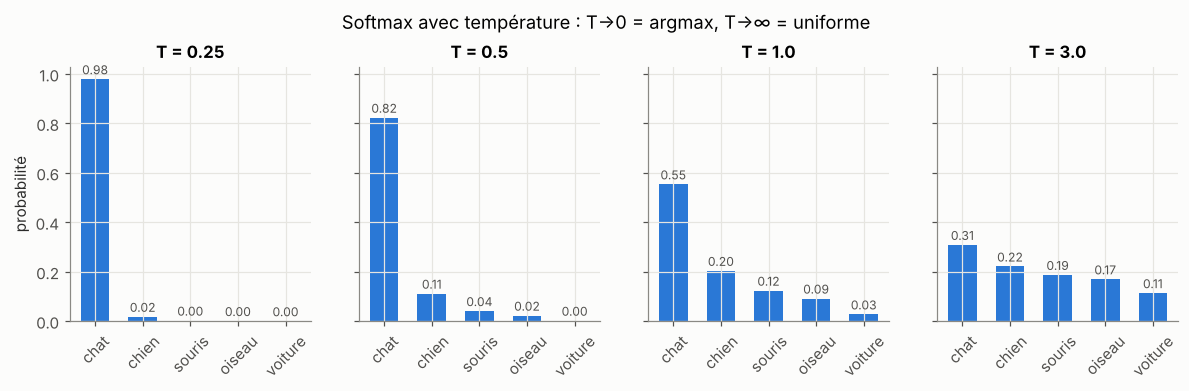

In [5]:
# Temperature: same logits, different sharpness
logits = np.array([2.0, 1.0, 0.5, 0.2, -1.0])
labels = ["chat", "chien", "souris", "oiseau", "voiture"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, T in zip(axes, [0.25, 0.5, 1.0, 3.0]):
    p = softmax(logits / T)
    ax.bar(labels, p, color=PALETTE[0], width=0.6)
    ax.set_title(f"T = {T}")
    ax.tick_params(axis="x", rotation=45)
    for i, v in enumerate(p):
        ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8, color="#52514e")
axes[0].set_ylabel("probabilité")
plt.suptitle("Softmax avec température : T→0 = argmax, T→∞ = uniforme", y=1.05)
plt.show()

## 4. Les fonctions de perte : d'où viennent-elles vraiment ?

### 💡 Intuition

On pourrait inventer n'importe quelle mesure d'erreur. Mais les deux pertes que tu utiliseras 95 % du temps, l'**erreur quadratique** (MSE) et l'**entropie croisée** (CE), ne sont pas arbitraires : elles découlent toutes deux du **maximum de vraisemblance**. On suppose que le modèle prédit une *distribution* sur $y$, et on cherche les paramètres qui rendent les données observées les plus probables.

### 📐 Maths : maximum de vraisemblance → perte

Maximiser la vraisemblance $\prod_i p_\theta(y_i\mid x_i)$ revient à minimiser la **log-vraisemblance négative** (NLL) :

$$
\mathcal{L}(\theta) = -\frac1N\sum_i \log p_\theta(y_i\mid x_i)
$$

**Régression, bruit gaussien.** Si $y = f_\theta(x) + \varepsilon$ avec $\varepsilon\sim\mathcal N(0,s^2)$ :
$$
-\log p_\theta(y\mid x) = \frac{(y-f_\theta(x))^2}{2s^2} + \text{cste} \quad\Longrightarrow\quad \text{MSE}
$$

**Classification binaire, loi de Bernoulli.** Si $p_\theta(y=1\mid x)=\hat p = \sigma(z)$ :
$$
-\log p_\theta(y\mid x) = -\big[y\log \hat p + (1-y)\log(1-\hat p)\big] \quad\Longrightarrow\quad \text{entropie croisée binaire (BCE)}
$$

**Classification à $K$ classes, loi catégorielle.** Avec $\hat p = \mathrm{softmax}(z)$ et $y$ encodé en *one-hot* :
$$
\ell(z, y) = -\sum_{k=1}^K y_k \log \hat p_k = -\log \hat p_{\text{vraie classe}}
$$

C'est **la** perte du NLP : un modèle de langue comme GPT est entraîné à minimiser l'entropie croisée du token suivant, rien d'autre.

> 📎 **Lien avec la théorie de l'information.** $H(y,\hat p) = -\sum_k y_k\log\hat p_k$ est l'entropie croisée entre la vraie distribution et la prédiction ; elle vaut $H(y) + \mathrm{KL}(y\,\|\,\hat p)$. Comme $H(y)$ ne dépend pas de $\theta$, minimiser la CE revient à minimiser la divergence KL. L'exponentielle de la CE moyenne d'un modèle de langue s'appelle la **perplexité** (module 4).

### 📐 Le gradient le plus important du deep learning : softmax + entropie croisée

Calculons $\partial \ell/\partial z_i$. D'abord la dérivée de la softmax :
$$
\frac{\partial \hat p_k}{\partial z_i} = \hat p_k(\delta_{ki} - \hat p_i)
$$
(où $\delta_{ki}=1$ si $k=i$, 0 sinon). Puis par la règle de la chaîne :
$$
\frac{\partial \ell}{\partial z_i} = -\sum_k \frac{y_k}{\hat p_k}\,\hat p_k(\delta_{ki}-\hat p_i) = -y_i + \hat p_i\underbrace{\sum_k y_k}_{=1} = \boxed{\hat p_i - y_i}
$$

**Le gradient par rapport aux logits est simplement « prédiction moins vérité ».** Magnifique, et numériquement stable. C'est pourquoi PyTorch fusionne softmax et CE dans `nn.CrossEntropyLoss`, qui attend des **logits bruts** (piège classique : ne mets pas de softmax avant !).

Même résultat en binaire : pour $\hat p=\sigma(z)$ et la BCE, $\partial\ell/\partial z = \hat p - y$.

### Pourquoi pas la MSE pour classer ?

Avec $\hat p=\sigma(z)$ et $\ell = \frac12(\hat p - y)^2$ : $\;\partial\ell/\partial z = (\hat p-y)\,\sigma'(z)$. Si le modèle est **très confiant et faux** ($z \ll 0$ alors que $y=1$), $\sigma'(z)\approx 0$ et le gradient est quasi nul : le modèle n'apprend plus de ses pires erreurs. La BCE n'a pas ce défaut, comme le montre la figure.

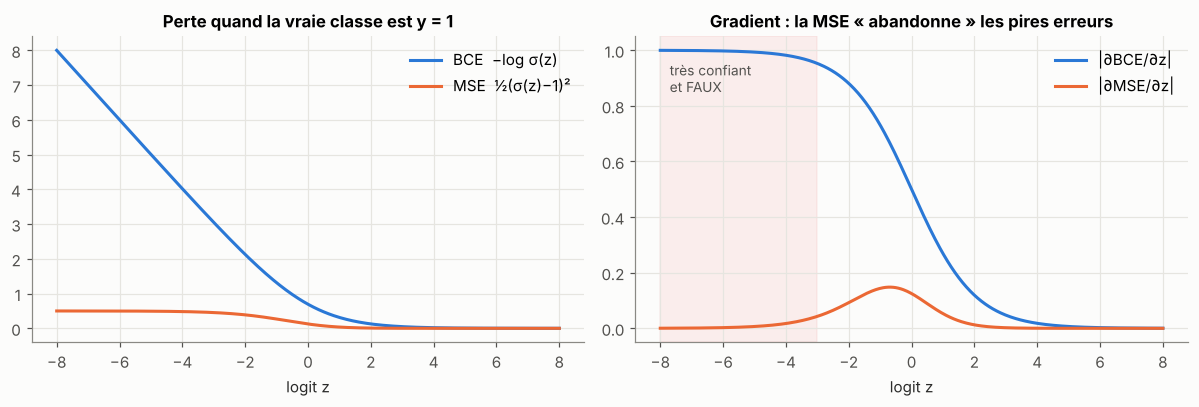

In [6]:
z = np.linspace(-8, 8, 400)
p = sig(z)
y = 1.0
bce = -np.log(p + 1e-12)
mse = 0.5 * (p - y) ** 2
g_bce = p - y
g_mse = (p - y) * p * (1 - p)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(z, bce, label="BCE  −log σ(z)")
axes[0].plot(z, mse, label="MSE  ½(σ(z)−1)²")
axes[0].set_title("Perte quand la vraie classe est y = 1"); axes[0].set_xlabel("logit z"); axes[0].legend()
axes[1].plot(z, np.abs(g_bce), label="|∂BCE/∂z|")
axes[1].plot(z, np.abs(g_mse), label="|∂MSE/∂z|")
axes[1].axvspan(-8, -3, color=PALETTE[7], alpha=0.08)
axes[1].text(-7.7, 0.85, "très confiant\net FAUX", color="#52514e", fontsize=9)
axes[1].set_title("Gradient : la MSE « abandonne » les pires erreurs"); axes[1].set_xlabel("logit z"); axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# A concrete cross-entropy computation, step by step
logits = np.array([2.0, 0.5, -1.0])   # model scores for 3 classes
target = 0                             # true class index
p = softmax(logits)
loss = -np.log(p[target])
grad = p.copy(); grad[target] -= 1     # p - one_hot(y)
print("probabilities :", p.round(4))
print(f"loss = -log p[{target}] = {loss:.4f}")
print("dL/dlogits    :", grad.round(4), " (sums to", grad.sum().round(6), ")")
print("uniform guess loss = log(3) =", np.log(3).round(4))

probabilities : [0.7856 0.1753 0.0391]
loss = -log p[0] = 0.2413
dL/dlogits    : [-0.2144  0.1753  0.0391]  (sums to 0.0 )
uniform guess loss = log(3) = 1.0986


> 💡 **Repère utile** : un modèle qui répond au hasard uniformément sur $K$ classes a une perte $\log K$. Si ta perte initiale est loin de $\log K$, ton initialisation ou ton code est suspect. Pour un modèle de langue avec 50 000 tokens, la perte de départ doit être proche de $\log 50000 \approx 10.8$.

## 5. La descente de gradient

### 💡 Intuition

Tu es sur une montagne dans un brouillard épais et tu veux descendre dans la vallée. Tu ne vois rien, mais tu sens la pente sous tes pieds. Stratégie : faire un pas dans la direction de plus forte descente, recommencer. Le **gradient** $\nabla\mathcal L(\theta)$ indique la direction de plus forte *montée* ; on va donc dans le sens opposé. La taille du pas est le **taux d'apprentissage** (*learning rate*) $\eta$, l'hyperparamètre le plus important de tout le deep learning.

### 📐 Maths

$$
\theta_{t+1} = \theta_t - \eta\,\nabla_\theta \mathcal{L}(\theta_t)
$$

**Pourquoi ça marche ?** Développement de Taylor à l'ordre 1 : $\mathcal L(\theta + \Delta) \approx \mathcal L(\theta) + \nabla\mathcal L^\top \Delta$. Parmi les pas $\Delta$ de norme fixée, celui qui fait le plus baisser $\mathcal L$ est $\Delta \propto -\nabla \mathcal L$ (Cauchy-Schwarz). Mais l'approximation n'est valable que **localement** : d'où un pas $\eta$ petit.

**Combien petit ?** Sur une parabole $\mathcal L(\theta)=\frac{\lambda}{2}\theta^2$, le gradient vaut $\lambda\theta$ et la mise à jour donne
$$
\theta_{t+1} = (1-\eta\lambda)\,\theta_t \quad\Longrightarrow\quad \theta_t = (1-\eta\lambda)^t\,\theta_0
$$
Convergence si et seulement si $|1-\eta\lambda|<1$, c'est-à-dire $0 < \eta < 2/\lambda$. Au-delà, **divergence**. En plusieurs dimensions, $\lambda$ devient les valeurs propres de la hessienne : $\eta$ est limité par la courbure **la plus forte** ($\eta<2/\lambda_{\max}$), alors que la vitesse de convergence est dictée par la plus faible. Le rapport $\kappa=\lambda_{\max}/\lambda_{\min}$ (le **conditionnement**) mesure à quel point le problème est difficile.

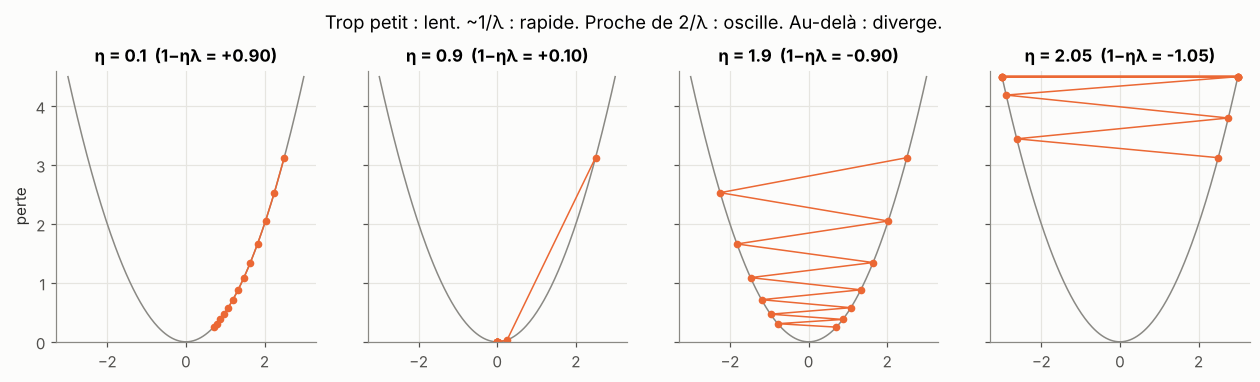

In [8]:
# 1D parabola L = 0.5 * lam * theta^2, lam = 1  => critical lr = 2
lam = 1.0
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
th = np.linspace(-3, 3, 200)
for ax, lr in zip(axes, [0.1, 0.9, 1.9, 2.05]):
    theta, path = 2.5, [2.5]
    for _ in range(12):
        theta = theta - lr * lam * theta
        path.append(theta)
    path = np.array(path)
    ax.plot(th, 0.5 * lam * th**2, color="#8a8984", lw=1)
    vis = np.clip(path, -3, 3)
    ax.plot(vis, 0.5 * lam * vis**2, "o-", color=PALETTE[1], ms=4, lw=1)
    ax.set_title(f"η = {lr}  (1−ηλ = {1 - lr * lam:+.2f})")
    ax.set_ylim(0, 4.6)
axes[0].set_ylabel("perte")
plt.suptitle("Trop petit : lent. ~1/λ : rapide. Proche de 2/λ : oscille. Au-delà : diverge.", y=1.05)
plt.show()

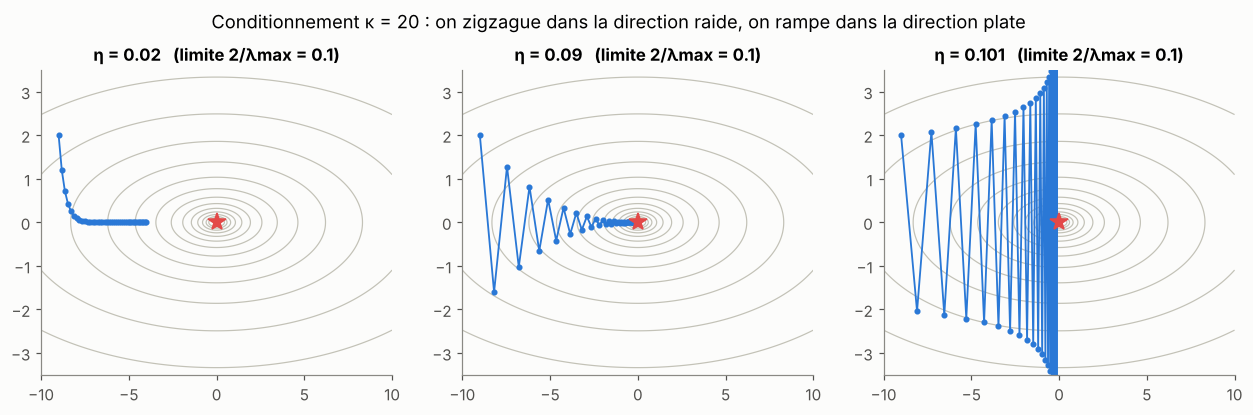

In [9]:
# 2D ill-conditioned quadratic: L = 0.5*(a x^2 + b y^2), kappa = b/a = 20
A = np.diag([1.0, 20.0])
L = lambda p: 0.5 * p @ A @ p
grad_L = lambda p: A @ p

def run_gd(lr, steps=40, start=(-9.0, 2.0)):
    p = np.array(start); path = [p.copy()]
    for _ in range(steps):
        p = p - lr * grad_L(p); path.append(p.copy())
    return np.array(path)

X1, X2 = np.meshgrid(np.linspace(-10, 10, 300), np.linspace(-3.5, 3.5, 300))
Z = 0.5 * (A[0, 0] * X1**2 + A[1, 1] * X2**2)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, lr in zip(axes, [0.02, 0.09, 0.101]):
    path = run_gd(lr)
    ax.contour(X1, X2, Z, levels=np.logspace(-1, 2.3, 14), colors="#c3c2b7", linewidths=0.8)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, lw=1.2, color=PALETTE[0])
    ax.plot(0, 0, "*", color=PALETTE[7], ms=12)
    ax.set_title(f"η = {lr}   (limite 2/λmax = 0.1)"); ax.set_ylim(-3.5, 3.5); ax.grid(False)
plt.suptitle("Conditionnement κ = 20 : on zigzague dans la direction raide, on rampe dans la direction plate", y=1.03)
plt.show()

**Leçon** : avec un seul taux d'apprentissage pour toutes les directions, on est coincé entre « oscille dans la vallée étroite » et « avance trop lentement le long de la vallée ». C'est la motivation directe de Momentum et Adam (section 6).

### Batch, stochastique, mini-batch

Calculer $\nabla \mathcal L$ exactement demande de parcourir **toutes** les données à chaque pas : impossible avec des millions de phrases. On estime donc le gradient sur un petit échantillon, un **mini-batch** $\mathcal B$ de taille $B$ (typiquement 16 à 4096) :

$$
g_t = \frac{1}{B}\sum_{i\in\mathcal B_t}\nabla_\theta\,\ell(f_\theta(x_i),y_i), \qquad \mathbb E[g_t] = \nabla\mathcal L(\theta_t)
$$

C'est un estimateur **sans biais** du vrai gradient, dont la variance décroît en $1/B$. Le bruit n'est pas qu'un défaut : il aide à sortir des minima pointus et sert de régularisation implicite. Une **époque** = un passage complet sur les données.

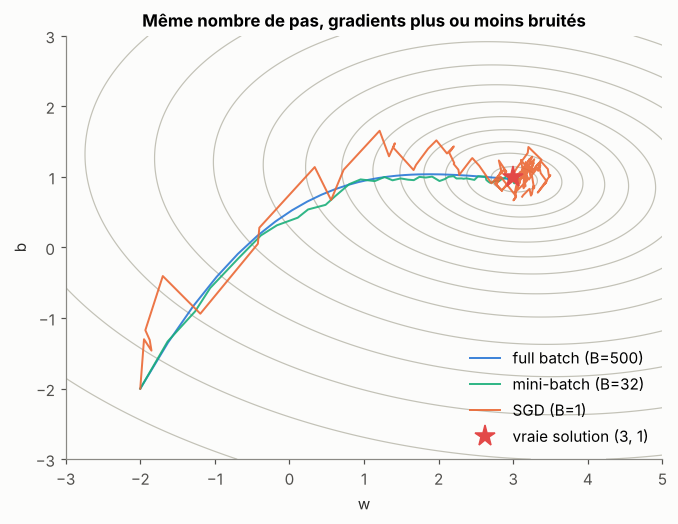

In [10]:
# Linear regression y = 3x + 1 + noise : full-batch vs SGD vs mini-batch
N = 500
x = rng.uniform(-1, 1, N)
y = 3 * x + 1 + rng.normal(0, 0.5, N)

def mse_grad(w, b, xb, yb):
    err = (w * xb + b) - yb
    return (err * xb).mean() * 2, err.mean() * 2

def train(batch_size, lr=0.1, steps=150, seed=0):
    r = np.random.default_rng(seed)
    w, b = -2.0, -2.0
    path = [(w, b)]
    for _ in range(steps):
        idx = r.choice(N, batch_size, replace=False)
        gw, gb = mse_grad(w, b, x[idx], y[idx])
        w, b = w - lr * gw, b - lr * gb
        path.append((w, b))
    return np.array(path)

W, Bb = np.meshgrid(np.linspace(-3, 5, 200), np.linspace(-3, 3, 200))
Lgrid = ((W[..., None] * x + Bb[..., None] - y) ** 2).mean(-1)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(W, Bb, Lgrid, levels=np.logspace(-0.6, 1.5, 15), colors="#c3c2b7", linewidths=0.8)
for bs, c, lab in [(N, PALETTE[0], f"full batch (B={N})"), (32, PALETTE[2], "mini-batch (B=32)"), (1, PALETTE[1], "SGD (B=1)")]:
    pth = train(bs)
    ax.plot(pth[:, 0], pth[:, 1], "-", lw=1.3, color=c, label=lab, alpha=0.9)
ax.plot(3, 1, "*", color=PALETTE[7], ms=14, label="vraie solution (3, 1)")
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.legend(loc="lower right"); ax.grid(False)
ax.set_title("Même nombre de pas, gradients plus ou moins bruités")
plt.show()

## 6. Les optimiseurs modernes

### 💡 Intuition

- **Momentum** : une bille qui roule accumule de la vitesse. Dans le zigzag de la vallée étroite, les oscillations transverses s'annulent d'un pas à l'autre, tandis que la composante le long de la vallée s'additionne. On va plus vite *et* plus droit.
- **RMSProp** : chaque paramètre reçoit son propre taux d'apprentissage, divisé par la taille typique de ses gradients récents. Direction raide → petits pas ; direction plate → grands pas. Cela corrige directement le problème du conditionnement.
- **Adam** = Momentum + RMSProp + une correction de biais. C'est l'optimiseur par défaut du NLP (sous la forme **AdamW**).

### 📐 Maths

Avec $g_t = \nabla\mathcal L(\theta_t)$ et des opérations **élément par élément** :

**Momentum** (heavy ball)
$$
v_t = \beta v_{t-1} + g_t, \qquad \theta_{t+1} = \theta_t - \eta\, v_t
$$
$v_t$ est une somme exponentiellement pondérée des gradients passés ; avec $\beta = 0.9$ elle « se souvient » d'environ $1/(1-\beta) = 10$ pas.

**RMSProp**
$$
s_t = \rho\, s_{t-1} + (1-\rho)\, g_t^2, \qquad \theta_{t+1} = \theta_t - \eta\,\frac{g_t}{\sqrt{s_t}+\epsilon}
$$

**Adam** (Kingma & Ba, 2015)
$$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1-\beta_1)\, g_t &&\text{(moment d'ordre 1 : direction)}\\
v_t &= \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2 &&\text{(moment d'ordre 2 : échelle)}\\
\hat m_t &= \frac{m_t}{1-\beta_1^t},\quad \hat v_t = \frac{v_t}{1-\beta_2^t} &&\text{(correction de biais)}\\
\theta_{t+1} &= \theta_t - \eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
\end{aligned}
$$
Valeurs usuelles : $\beta_1=0.9$, $\beta_2=0.999$ (ou $0.95$ pour les LLM), $\epsilon=10^{-8}$.

**Pourquoi la correction de biais ?** On initialise $m_0 = 0$. En déroulant la récurrence, $m_t = (1-\beta_1)\sum_{k=1}^t \beta_1^{t-k} g_k$. Si les gradients sont stationnaires, $\mathbb E[m_t] = \mathbb E[g]\,(1-\beta_1)\sum_{k=0}^{t-1}\beta_1^k = \mathbb E[g]\,(1-\beta_1^t)$. Les premiers $m_t$ sont donc biaisés vers 0 ; diviser par $(1-\beta_1^t)$ corrige exactement ce biais.

**AdamW** (Loshchilov & Hutter, 2019) : la régularisation L2 ajoutée au gradient interagit mal avec la normalisation d'Adam. AdamW applique la décroissance des poids **séparément** : $\theta_{t+1} = \theta_t - \eta\big(\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon} + \lambda\,\theta_t\big)$. C'est le standard pour BERT, GPT, ESM, etc.

SGD (η=1e-3)                 final point = [-1.039  1.088]   loss = 4.16e+00
Momentum (η=1e-3, β=0.9)     final point = [0.958 0.917]   loss = 1.78e-03
RMSProp (η=1e-2)             final point = [0.559 0.322]   loss = 2.02e-01
Adam (η=5e-2)                final point = [0.81  0.655]   loss = 3.62e-02


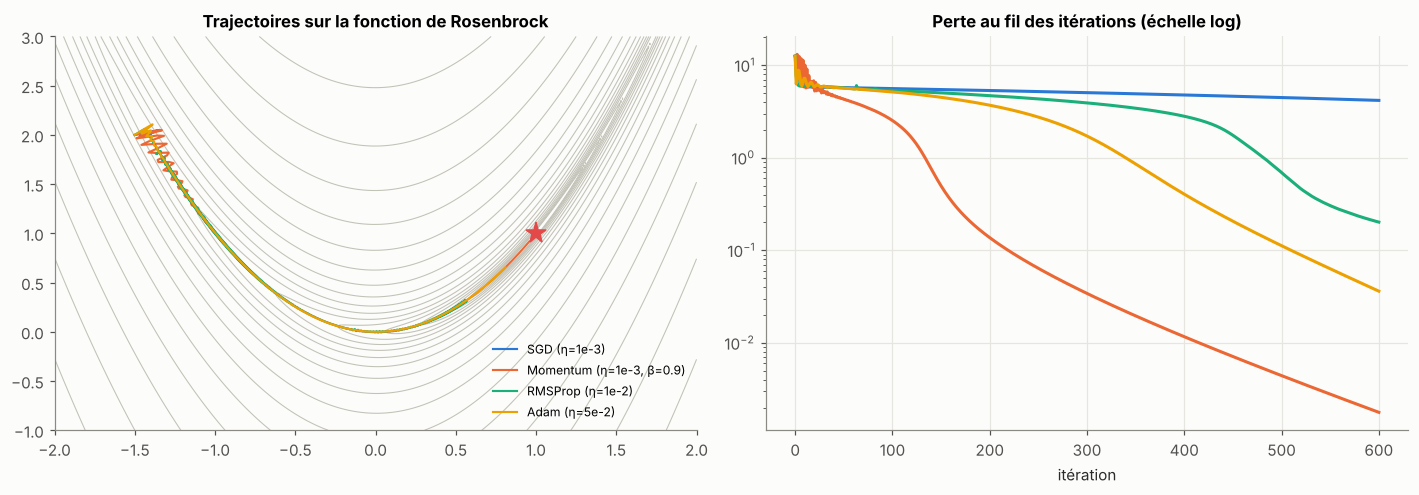

In [11]:
class SGD:
    def __init__(self, lr): self.lr = lr
    def step(self, p, g): return p - self.lr * g

class Momentum:
    def __init__(self, lr, beta=0.9): self.lr, self.beta, self.v = lr, beta, 0.0
    def step(self, p, g):
        self.v = self.beta * self.v + g
        return p - self.lr * self.v

class RMSProp:
    def __init__(self, lr, rho=0.9, eps=1e-8): self.lr, self.rho, self.eps, self.s = lr, rho, eps, 0.0
    def step(self, p, g):
        self.s = self.rho * self.s + (1 - self.rho) * g**2
        return p - self.lr * g / (np.sqrt(self.s) + self.eps)

class Adam:
    def __init__(self, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps
        self.m, self.v, self.t = 0.0, 0.0, 0
    def step(self, p, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g**2
        m_hat = self.m / (1 - self.b1**self.t)
        v_hat = self.v / (1 - self.b2**self.t)
        return p - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

# Rosenbrock function: a curved, narrow valley; minimum at (1, 1)
rosen = lambda p: (1 - p[0])**2 + 100 * (p[1] - p[0]**2)**2
rosen_grad = lambda p: np.array([-2 * (1 - p[0]) - 400 * p[0] * (p[1] - p[0]**2), 200 * (p[1] - p[0]**2)])

def optimize(opt, steps=600, start=(-1.5, 2.0)):
    p = np.array(start, dtype=float); path = [p.copy()]
    for _ in range(steps):
        p = opt.step(p, rosen_grad(p)); path.append(p.copy())
    return np.array(path)

runs = {
    "SGD (η=1e-3)": optimize(SGD(1e-3)),
    "Momentum (η=1e-3, β=0.9)": optimize(Momentum(1e-3)),
    "RMSProp (η=1e-2)": optimize(RMSProp(1e-2)),
    "Adam (η=5e-2)": optimize(Adam(5e-2)),
}
X1, X2 = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
Zr = (1 - X1)**2 + 100 * (X2 - X1**2)**2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].contour(X1, X2, Zr, levels=np.logspace(-1, 3.5, 20), colors="#c3c2b7", linewidths=0.7)
for (name, pth), c in zip(runs.items(), PALETTE):
    axes[0].plot(pth[:, 0], pth[:, 1], "-", lw=1.4, color=c, label=name)
    axes[1].semilogy([rosen(q) for q in pth], color=c, label=name)
axes[0].plot(1, 1, "*", color=PALETTE[7], ms=14); axes[0].set_title("Trajectoires sur la fonction de Rosenbrock"); axes[0].grid(False)
axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_title("Perte au fil des itérations (échelle log)"); axes[1].set_xlabel("itération")
plt.tight_layout(); plt.show()
for name, pth in runs.items():
    print(f"{name:28s} final point = {pth[-1].round(3)}   loss = {rosen(pth[-1]):.2e}")

> ⚠️ **Lecture critique** : sur ce problème jouet, le classement dépend énormément des taux d'apprentissage choisis. Ne conclus jamais « Adam > SGD » d'une seule figure. Ce qui est robuste : Adam est **beaucoup moins sensible** au choix de $\eta$ et à l'échelle des paramètres, ce qui explique sa domination en NLP où les gradients des embeddings de mots rares et fréquents ont des échelles très différentes.

### Planification du taux d'apprentissage : warmup + décroissance cosinus

En pratique, $\eta$ varie pendant l'entraînement. Le schéma standard pour les Transformers :
- **warmup linéaire** pendant les premiers pas (au début, les estimations $v_t$ d'Adam sont bruitées et les gradients énormes : de grands pas déstabiliseraient le modèle) ;
- puis **décroissance cosinus** jusqu'à une petite valeur, pour affiner la solution.

$$
\eta_t = \begin{cases} \eta_{\max}\,\dfrac{t}{T_w} & t < T_w \\[2mm] \eta_{\min} + \frac12(\eta_{\max}-\eta_{\min})\left(1+\cos\left(\pi\,\dfrac{t-T_w}{T-T_w}\right)\right) & t\ge T_w\end{cases}
$$

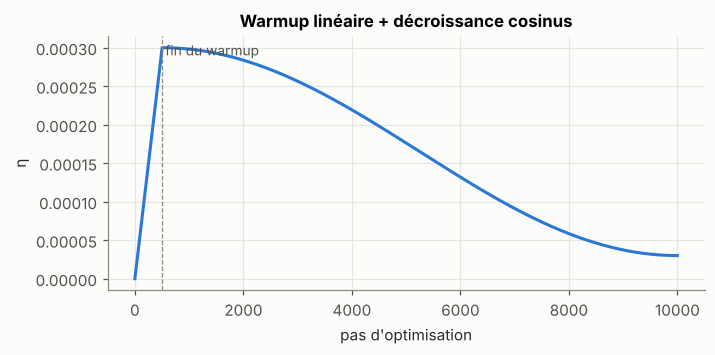

In [12]:
def lr_schedule(t, T=10_000, warmup=500, lr_max=3e-4, lr_min=3e-5):
    if t < warmup:
        return lr_max * t / warmup
    progress = (t - warmup) / (T - warmup)
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + np.cos(np.pi * progress))

ts = np.arange(10_000)
plt.figure(figsize=(7, 3))
plt.plot(ts, [lr_schedule(t) for t in ts], color=PALETTE[0])
plt.axvline(500, color="#8a8984", lw=0.8, ls="--"); plt.text(560, 2.9e-4, "fin du warmup", color="#52514e", fontsize=9)
plt.title("Warmup linéaire + décroissance cosinus"); plt.xlabel("pas d'optimisation"); plt.ylabel("η")
plt.show()

## 7. La rétropropagation

### 💡 Intuition

Un réseau est une **composition** de fonctions simples. Pour savoir comment un poids enfoui au fond du réseau influence la perte, on applique la règle de la chaîne : « si je bouge ce poids un peu, de combien bouge la sortie de sa couche ? Et de combien cela fait-il bouger la couche suivante ? … jusqu'à la perte ». La rétropropagation organise ce calcul **à rebours**, de la perte vers les entrées, en **réutilisant** les dérivées intermédiaires. C'est ce qui rend l'entraînement de réseaux à des milliards de paramètres possible : le gradient complet coûte à peu près **le prix de deux évaluations du réseau**, quel que soit le nombre de paramètres.

### 📐 Maths : la règle de la chaîne sur un graphe de calcul

Soit $L = f(g(h(x)))$. En posant $u = h(x)$, $v = g(u)$ :
$$
\frac{dL}{dx} = \frac{dL}{dv}\cdot\frac{dv}{du}\cdot\frac{du}{dx}
$$
On calcule de **gauche à droite** : on part de $\frac{dL}{dL}=1$ et chaque nœud reçoit un gradient « amont » qu'il multiplie par sa dérivée locale avant de le transmettre. Si un nœud alimente plusieurs nœuds, **ses gradients s'additionnent** (règle de la chaîne multivariée).

**Pourquoi « à rebours » ?** On a une seule sortie scalaire (la perte) et des millions d'entrées (les paramètres). Le mode inverse calcule toutes les dérivées $\partial L/\partial\theta_j$ en une seule passe arrière ; le mode direct demanderait une passe par paramètre.

**Exemple numérique à la main.** $L = (w x + b - y)^2$ avec $x=2, w=3, b=1, y=5$.

| Passe avant | | Passe arrière | |
|---|---|---|---|
| $u = wx = 6$ | | $\partial L/\partial e = 2e = 4$ | |
| $s = u + b = 7$ | | $\partial L/\partial s = 4 \cdot 1 = 4$ | |
| $e = s - y = 2$ | | $\partial L/\partial b = 4\cdot 1 = 4$ | |
| $L = e^2 = 4$ | | $\partial L/\partial w = 4\cdot x = 8$ | |

### 💻 Un moteur d'autodiff en 60 lignes

Le meilleur moyen de démystifier PyTorch : coder un mini-`autograd` (inspiré de *micrograd* d'A. Karpathy). Chaque `Value` garde sa valeur, son gradient, ses parents et une fonction `_backward` qui applique la dérivée locale.

In [13]:
class Value:
    """A scalar that remembers how it was computed, so it can backpropagate."""

    def __init__(self, data, _parents=(), _op="", label=""):
        self.data = float(data)
        self.grad = 0.0
        self._backward = lambda: None
        self._parents = set(_parents)
        self._op, self.label = _op, label

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward():
            self.grad += out.grad          # d(a+b)/da = 1
            other.grad += out.grad         # d(a+b)/db = 1
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward():
            self.grad += other.data * out.grad   # d(ab)/da = b
            other.grad += self.data * out.grad   # d(ab)/db = a
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward():
            self.grad += k * self.data ** (k - 1) * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        t = np.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        out = Value(np.exp(self.data), (self,), "exp")
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def relu(self):
        out = Value(max(0.0, self.data), (self,), "relu")
        def _backward():
            self.grad += (self.data > 0) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # topological order: every node is processed after all nodes that depend on it
        topo, visited = [], set()
        def build(v):
            if v not in visited:
                visited.add(v)
                for p in v._parents:
                    build(p)
                topo.append(v)
        build(self)
        self.grad = 1.0
        for v in reversed(topo):
            v._backward()

    __radd__ = __add__
    __rmul__ = __mul__
    def __neg__(self): return self * -1
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return (-self) + other
    def __truediv__(self, other): return self * other ** -1
    def __repr__(self): return f"Value({self.label or self._op}: data={self.data:.4f}, grad={self.grad:.4f})"

# The hand-computed example: L = (w*x + b - y)^2
x_, w_, b_, y_ = Value(2.0, label="x"), Value(3.0, label="w"), Value(1.0, label="b"), Value(5.0, label="y")
L_ = (w_ * x_ + b_ - y_) ** 2
L_.backward()
print(L_)
print(w_, b_, x_, sep="\n")

Value(**2: data=4.0000, grad=1.0000)
Value(w: data=3.0000, grad=8.0000)
Value(b: data=1.0000, grad=4.0000)
Value(x: data=2.0000, grad=12.0000)


On retrouve exactement $\partial L/\partial w = 8$ et $\partial L/\partial b = 4$. Essayons un vrai neurone avec tanh et vérifions par **différences finies** :

$$
\frac{\partial L}{\partial \theta} \approx \frac{L(\theta+h)-L(\theta-h)}{2h}\qquad(\text{erreur en } O(h^2))
$$

In [14]:
def neuron_loss(w1, w2, b, x1=0.5, x2=-1.5, y=0.8):
    a = (w1 * x1 + w2 * x2 + b).tanh()
    return (a - y) ** 2

w1, w2, bb = Value(0.7, label="w1"), Value(-0.3, label="w2"), Value(0.1, label="b")
loss_v = neuron_loss(w1, w2, bb)
loss_v.backward()

h = 1e-5
f = lambda a, c, d: neuron_loss(Value(a), Value(c), Value(d)).data
num = [
    (f(0.7 + h, -0.3, 0.1) - f(0.7 - h, -0.3, 0.1)) / (2 * h),
    (f(0.7, -0.3 + h, 0.1) - f(0.7, -0.3 - h, 0.1)) / (2 * h),
    (f(0.7, -0.3, 0.1 + h) - f(0.7, -0.3, 0.1 - h)) / (2 * h),
]
for v, n in zip([w1, w2, bb], num):
    print(f"{v.label}: backprop = {v.grad:+.8f}   finite diff = {n:+.8f}")

w1: backprop = -0.04075602   finite diff = -0.04075602
w2: backprop = +0.12226806   finite diff = +0.12226806
b: backprop = -0.08151204   finite diff = -0.08151204


> 🎯 **Ce que fait PyTorch n'est pas plus magique que ça** : `torch.Tensor` joue le rôle de `Value`, mais sur des tableaux, avec des centaines d'opérations et des noyaux GPU. `loss.backward()` fait le tri topologique et appelle les `_backward`. Et `+=` dans les `_backward` explique pourquoi en PyTorch **les gradients s'accumulent** : il faut appeler `optimizer.zero_grad()` à chaque pas.

### 📐 Rétropropagation matricielle d'une couche dense

Travailler scalaire par scalaire est trop lent. Pour une couche $Z = XW + b$ avec $X\in\mathbb R^{B\times d}$, $W\in\mathbb R^{d\times h}$, et un gradient amont $\delta = \partial L/\partial Z \in\mathbb R^{B\times h}$ :

$$
\boxed{\frac{\partial L}{\partial W} = X^\top \delta \;\in \mathbb R^{d\times h}}\qquad
\boxed{\frac{\partial L}{\partial b} = \sum_{i=1}^B \delta_{i,:} \;\in\mathbb R^{h}}\qquad
\boxed{\frac{\partial L}{\partial X} = \delta\, W^\top \;\in\mathbb R^{B\times d}}
$$

**Astuce mnémotechnique** : le gradient d'un tenseur a **toujours la même forme** que ce tenseur. Il n'y a souvent qu'une seule façon de combiner $X$, $W$, $\delta$ pour obtenir la bonne forme : vérifie toujours les dimensions.

Pour une activation élément par élément $A=\phi(Z)$ : $\partial L/\partial Z = \partial L/\partial A \odot \phi'(Z)$ (produit de Hadamard). Pour ReLU : on met à zéro le gradient là où $Z\le 0$.

Pour la dernière couche (softmax + CE moyennée sur le batch) : $\delta = \frac1B(\hat P - Y)$, avec $Y$ en one-hot. Le $\frac1B$ vient de la moyenne.

## 8. Un MLP complet en NumPy, de zéro

On assemble tout : un réseau à 2 couches cachées, la softmax-CE, la rétropropagation matricielle, la vérification du gradient, puis l'entraînement sur un problème non linéaire : **trois spirales entrelacées**.

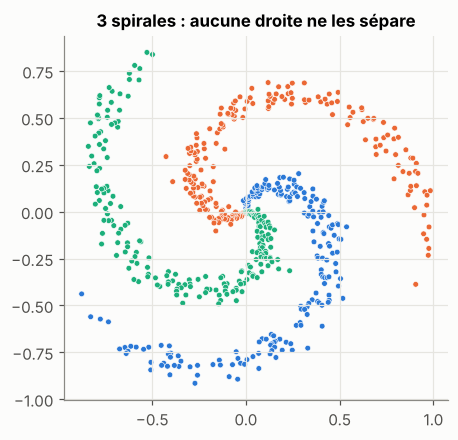

In [15]:
def make_spirals(n_per_class=200, n_classes=3, noise=0.2, seed=0):
    r = np.random.default_rng(seed)
    X, y = [], []
    for k in range(n_classes):
        t = np.linspace(0.0, 1, n_per_class)
        angle = np.linspace(k * 4, (k + 1) * 4, n_per_class) + r.normal(0, noise, n_per_class)
        X.append(np.c_[t * np.sin(angle), t * np.cos(angle)])
        y.append(np.full(n_per_class, k))
    return np.vstack(X), np.concatenate(y)

X_spiral, y_spiral = make_spirals()
cmap3 = ListedColormap(PALETTE[:3])
plt.figure(figsize=(4.5, 4.5))
plt.scatter(X_spiral[:, 0], X_spiral[:, 1], c=y_spiral, cmap=cmap3, s=14, edgecolors="white", linewidths=0.4)
plt.title("3 spirales : aucune droite ne les sépare"); plt.gca().set_aspect("equal")
plt.show()

In [16]:
class MLP:
    """Fully-connected network: [Linear -> ReLU] * n_hidden -> Linear (logits)."""

    def __init__(self, sizes, seed=0, init="he"):
        r = np.random.default_rng(seed)
        self.W, self.b = [], []
        for d_in, d_out in zip(sizes[:-1], sizes[1:]):
            std = np.sqrt(2.0 / d_in) if init == "he" else init
            self.W.append(r.normal(0, std, (d_in, d_out)))
            self.b.append(np.zeros(d_out))

    def forward(self, X):
        self.cache = [X]                      # store activations for backward
        A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            A = np.maximum(0, Z) if i < len(self.W) - 1 else Z
            self.cache.append(Z)
        return A                              # logits

    def loss_and_grads(self, X, y, l2=0.0):
        B = X.shape[0]
        logits = self.forward(X)
        P = softmax(logits)
        loss = -np.log(P[np.arange(B), y] + 1e-12).mean()
        loss += 0.5 * l2 * sum((W**2).sum() for W in self.W)

        dZ = P.copy()
        dZ[np.arange(B), y] -= 1              # softmax + CE: P - Y
        dZ /= B
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            A_prev = self.cache[i] if i == 0 else np.maximum(0, self.cache[i])
            gW[i] = A_prev.T @ dZ + l2 * self.W[i]
            gb[i] = dZ.sum(axis=0)
            if i > 0:
                dA = dZ @ self.W[i].T
                dZ = dA * (self.cache[i] > 0)  # ReLU derivative
        return loss, gW, gb

    def predict(self, X):
        return self.forward(X).argmax(axis=1)

> 🔍 **Détail subtil** : `self.cache[i]` contient la pré-activation $Z$ de la couche $i$ (pour $i\ge1$) et l'entrée $X$ pour $i=0$. L'activation de la couche précédente est donc $\mathrm{ReLU}(Z_i)$. Garder les pré-activations permet de calculer à la fois $A$ et la dérivée de ReLU.

**Vérification du gradient (gradient checking).** Avant d'entraîner quoi que ce soit, on vérifie la rétropropagation contre les différences finies, paramètre par paramètre. Critère : l'erreur relative $\frac{\lVert g_{\text{bp}}-g_{\text{num}}\rVert}{\lVert g_{\text{bp}}\rVert+\lVert g_{\text{num}}\rVert}$ doit être de l'ordre de $10^{-7}$ ou moins en `float64`. Au-dessus de $10^{-4}$, il y a un bug.

> 🔍 On calcule l'erreur relative sur **toute la matrice** (normes) plutôt qu'entrée par entrée : pour un gradient minuscule (disons $10^{-8}$), l'arrondi des différences finies ($\approx 10^{-16}/h$) donne une erreur relative énorme alors que le code est juste. C'est un faux positif classique.

In [17]:
net = MLP([2, 16, 16, 3], seed=1)
Xs, ys = X_spiral[:20], y_spiral[:20]
_, gW, gb = net.loss_and_grads(Xs, ys, l2=1e-3)

def numerical_grad(net, layer, X, y, l2, h=1e-5):
    G = np.zeros_like(net.W[layer])
    for i in range(G.shape[0]):
        for j in range(G.shape[1]):
            old = net.W[layer][i, j]
            net.W[layer][i, j] = old + h; lp, _, _ = net.loss_and_grads(X, y, l2=l2)
            net.W[layer][i, j] = old - h; lm, _, _ = net.loss_and_grads(X, y, l2=l2)
            net.W[layer][i, j] = old
            G[i, j] = (lp - lm) / (2 * h)
    return G

for layer in range(len(net.W)):
    G_num = numerical_grad(net, layer, Xs, ys, l2=1e-3)
    rel = np.linalg.norm(gW[layer] - G_num) / (np.linalg.norm(gW[layer]) + np.linalg.norm(G_num))
    print(f"layer {layer} W{net.W[layer].shape}: relative error = {rel:.2e}", "✅" if rel < 1e-6 else "❌")

layer 0 W(2, 16): relative error = 2.56e-09 ✅
layer 1 W(16, 16): relative error = 1.14e-09 ✅
layer 2 W(16, 3): relative error = 3.28e-09 ✅


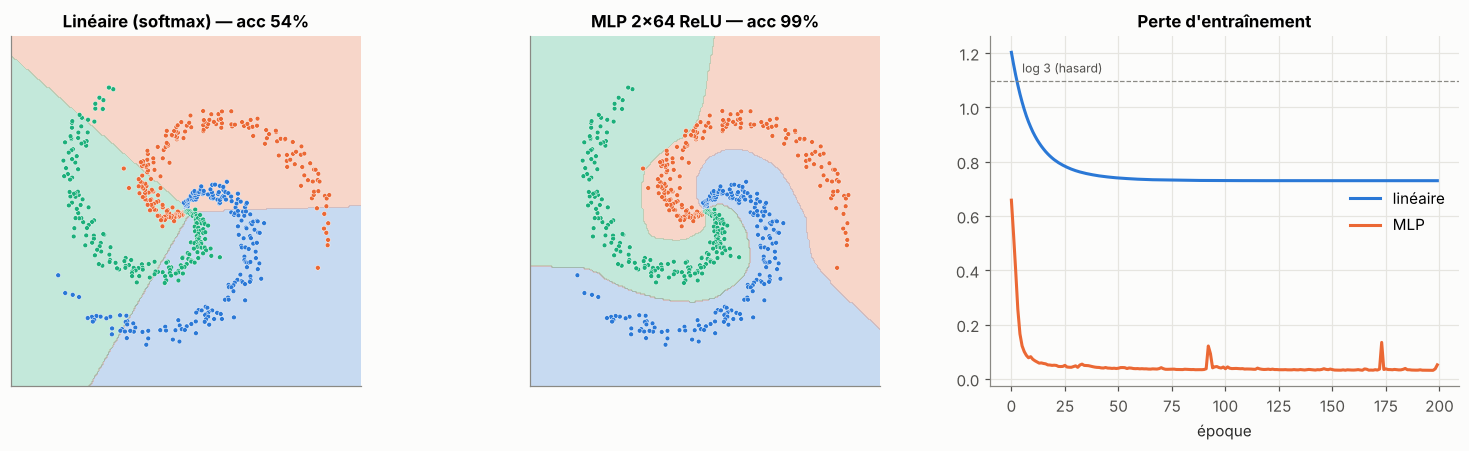

In [18]:
def train_numpy(net, X, y, opt_cls, lr, epochs=300, batch_size=64, l2=1e-4, seed=0, X_val=None, y_val=None):
    r = np.random.default_rng(seed)
    params = net.W + net.b
    opts = [opt_cls(lr) for _ in params]
    hist = {"loss": [], "acc": [], "val_acc": []}
    for ep in range(epochs):
        perm = r.permutation(len(X))
        for k in range(0, len(X), batch_size):
            idx = perm[k:k + batch_size]
            loss, gW, gb = net.loss_and_grads(X[idx], y[idx], l2=l2)
            grads = gW + gb
            for n, (p, g, o) in enumerate(zip(params, grads, opts)):
                params[n][...] = o.step(p, g)     # in-place update keeps net.W / net.b in sync
        full_loss, _, _ = net.loss_and_grads(X, y, l2=l2)
        hist["loss"].append(full_loss)
        hist["acc"].append((net.predict(X) == y).mean())
        if X_val is not None:
            hist["val_acc"].append((net.predict(X_val) == y_val).mean())
    return hist

def plot_boundary(net, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 250), np.linspace(-1.2, 1.2, 250))
    pred = net.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, pred, alpha=0.25, cmap=cmap3, levels=[-0.5, 0.5, 1.5, 2.5])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap3, s=10, edgecolors="white", linewidths=0.3)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])

linear = MLP([2, 3], seed=0)
h_lin = train_numpy(linear, X_spiral, y_spiral, Adam, lr=1e-2, epochs=200)
deep = MLP([2, 64, 64, 3], seed=0)
h_deep = train_numpy(deep, X_spiral, y_spiral, Adam, lr=1e-2, epochs=200)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
plot_boundary(linear, X_spiral, y_spiral, axes[0], f"Linéaire (softmax) — acc {h_lin['acc'][-1]:.0%}")
plot_boundary(deep, X_spiral, y_spiral, axes[1], f"MLP 2×64 ReLU — acc {h_deep['acc'][-1]:.0%}")
axes[2].plot(h_lin["loss"], label="linéaire"); axes[2].plot(h_deep["loss"], label="MLP")
axes[2].axhline(np.log(3), color="#8a8984", ls="--", lw=0.8); axes[2].text(5, np.log(3) + 0.03, "log 3 (hasard)", fontsize=8, color="#52514e")
axes[2].set_title("Perte d'entraînement"); axes[2].set_xlabel("époque"); axes[2].legend()
plt.tight_layout(); plt.show()

Le modèle linéaire plafonne (il ne peut tracer que 3 demi-plans), alors que le MLP « plie » l'espace et épouse les spirales. **Tu viens d'écrire, de zéro, tout ce que fait un framework de deep learning pour un MLP.**

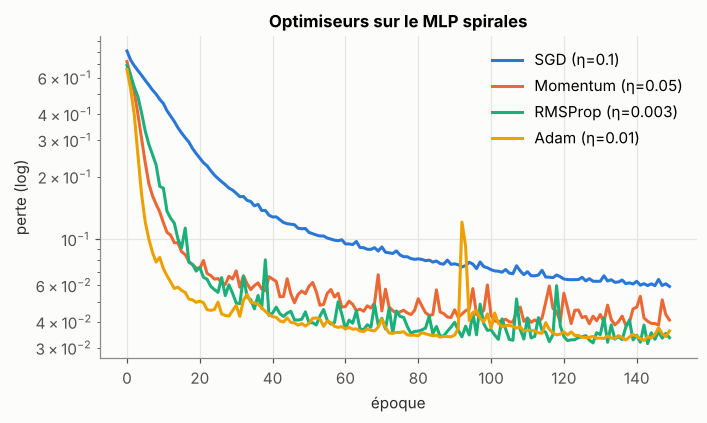

In [19]:
# Compare optimizers on the same MLP and data
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, cls, lr), c in zip([("SGD", SGD, 0.1), ("Momentum", Momentum, 0.05), ("RMSProp", RMSProp, 3e-3), ("Adam", Adam, 1e-2)], PALETTE):
    hst = train_numpy(MLP([2, 64, 64, 3], seed=0), X_spiral, y_spiral, cls, lr=lr, epochs=150)
    ax.plot(hst["loss"], color=c, label=f"{name} (η={lr})")
ax.set_yscale("log"); ax.set_xlabel("époque"); ax.set_ylabel("perte (log)"); ax.legend()
ax.set_title("Optimiseurs sur le MLP spirales")
plt.show()

## 9. L'initialisation des poids

### 💡 Intuition

Deux pièges :
1. **Initialiser tous les poids à la même valeur** (par exemple 0) : tous les neurones d'une couche calculent la même chose et reçoivent le même gradient, ils restent identiques à jamais. Il faut **briser la symétrie** avec de l'aléatoire.
2. **Mauvaise échelle** : si les poids sont trop petits, le signal rétrécit à chaque couche jusqu'à disparaître ; trop grands, il explose (ou sature les tanh). Dans les deux cas, les gradients font de même.

### 📐 Maths : propager la variance

Pour un neurone $z = \sum_{j=1}^{n_{in}} w_j x_j$ avec $w_j$ et $x_j$ indépendants, centrés :
$$
\mathrm{Var}(z) = n_{in}\,\mathrm{Var}(w)\,\mathrm{Var}(x)
$$
Pour garder $\mathrm{Var}(z)=\mathrm{Var}(x)$ d'une couche à l'autre, il faut $\mathrm{Var}(w) = 1/n_{in}$ (**LeCun**). En équilibrant aussi la passe arrière (qui fait intervenir $n_{out}$), on obtient **Xavier/Glorot** : $\mathrm{Var}(w)=\frac{2}{n_{in}+n_{out}}$, adaptée à tanh.

Avec ReLU, la moitié des pré-activations est mise à zéro, donc $\mathbb E[\mathrm{ReLU}(z)^2] = \frac12\mathrm{Var}(z)$. Pour compenser : $\mathrm{Var}(w)=2/n_{in}$, c'est l'initialisation **He/Kaiming**, utilisée dans notre classe `MLP`.

> Les Transformers utilisent en plus des **LayerNorm** et des **connexions résiduelles** (module 6), qui rendent le réseau beaucoup moins sensible à l'initialisation. Mais l'idée de « préserver l'échelle du signal » reste centrale. GPT-2 réduit même l'initialisation des projections résiduelles d'un facteur $1/\sqrt{2N_{\text{couches}}}$ pour cette raison.

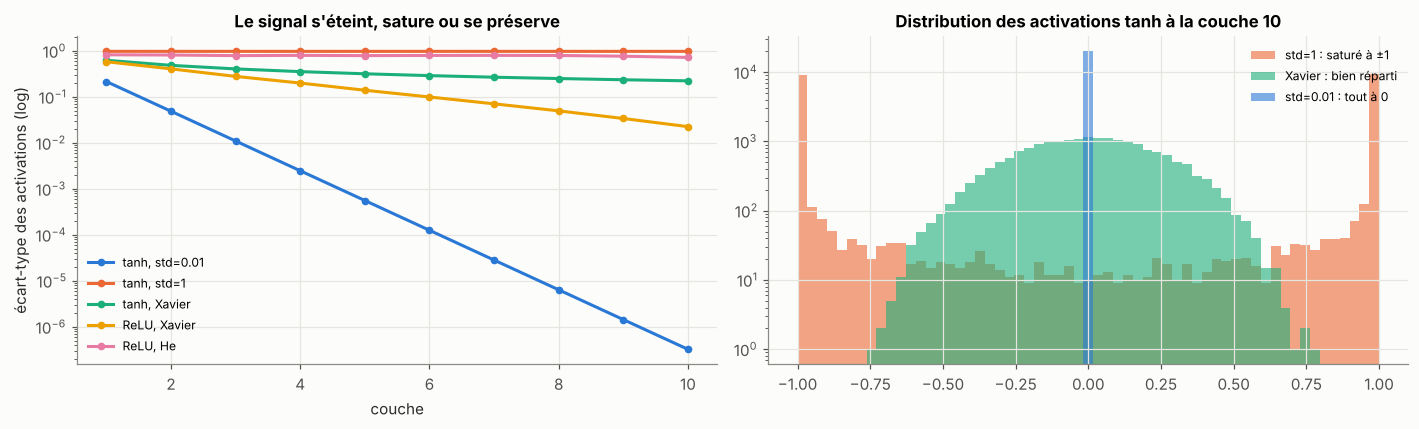

In [20]:
def activation_stats(std_fn, act, n_layers=10, width=512, n=1000, seed=0):
    r = np.random.default_rng(seed)
    A = r.normal(0, 1, (n, width))
    stds, hists = [], []
    for _ in range(n_layers):
        W = r.normal(0, std_fn(width), (width, width))
        A = act(A @ W)
        stds.append(A.std()); hists.append(A.ravel()[:20000])
    return stds, hists

relu = lambda z: np.maximum(0, z)
configs = [
    ("tanh, std=0.01", lambda n: 0.01, np.tanh),
    ("tanh, std=1", lambda n: 1.0, np.tanh),
    ("tanh, Xavier", lambda n: np.sqrt(1 / n), np.tanh),
    ("ReLU, Xavier", lambda n: np.sqrt(1 / n), relu),
    ("ReLU, He", lambda n: np.sqrt(2 / n), relu),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, sfn, act), c in zip(configs, PALETTE):
    stds, hists = activation_stats(sfn, act)
    axes[0].semilogy(range(1, 11), stds, "o-", ms=4, color=c, label=name)
axes[0].set_xlabel("couche"); axes[0].set_ylabel("écart-type des activations (log)")
axes[0].set_title("Le signal s'éteint, sature ou se préserve"); axes[0].legend(fontsize=8)

_, h_small = activation_stats(lambda n: 0.01, np.tanh)
_, h_big = activation_stats(lambda n: 1.0, np.tanh)
_, h_xav = activation_stats(lambda n: np.sqrt(1 / n), np.tanh)
bins = np.linspace(-1, 1, 60)
axes[1].hist(h_big[-1], bins=bins, alpha=0.6, label="std=1 : saturé à ±1", color=PALETTE[1])
axes[1].hist(h_xav[-1], bins=bins, alpha=0.6, label="Xavier : bien réparti", color=PALETTE[2])
axes[1].hist(h_small[-1], bins=bins, alpha=0.6, label="std=0.01 : tout à 0", color=PALETTE[0])
axes[1].set_yscale("log"); axes[1].set_title("Distribution des activations tanh à la couche 10"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

> 🔎 **Piège de lecture** : la courbe « tanh, std=1 » paraît stable (écart-type ≈ 1), mais l'histogramme montre pourquoi : presque toutes les activations sont **collées à ±1**, là où la dérivée de tanh est nulle. Le signal avant est « préservé », mais aucun gradient ne passe en arrière. Une seule statistique ne suffit jamais : regarde les distributions.

## 10. Généralisation et régularisation

### 💡 Intuition

Un réseau assez gros peut **apprendre par cœur** ses données d'entraînement, bruit compris : c'est le **sur-apprentissage** (*overfitting*). On le détecte en mesurant la performance sur un **jeu de validation** jamais utilisé pour l'entraînement. La règle d'or : on choisit les hyperparamètres sur la validation, et on ne touche au **jeu de test** qu'une seule fois, à la toute fin.

Outils pour lutter contre le sur-apprentissage :

| Technique | Idée | Formule / mise en œuvre |
|---|---|---|
| **Plus de données** | le meilleur régularisateur | augmentation, pré-entraînement (module 7) |
| **L2 / weight decay** | préférer de petits poids, fonctions plus lisses | $\mathcal L + \frac\lambda2\lVert\theta\rVert^2$ |
| **Dropout** | empêcher la co-adaptation des neurones | masque aléatoire à l'entraînement |
| **Early stopping** | arrêter quand la validation se dégrade | garder le meilleur checkpoint |
| **Taille du modèle** | moins de capacité | moins de couches / neurones |

### 📐 Maths

**L2 = a priori gaussien.** Ajouter $\frac\lambda2\lVert\theta\rVert^2$ revient à faire du maximum *a posteriori* avec $\theta\sim\mathcal N(0, \lambda^{-1}I)$. Le gradient devient $\nabla\mathcal L + \lambda\theta$, et la mise à jour en SGD :
$$
\theta \leftarrow (1-\eta\lambda)\,\theta - \eta\nabla\mathcal L
$$
d'où le nom *weight decay* : à chaque pas, les poids rétrécissent d'un facteur $(1-\eta\lambda)$.

**Dropout inversé.** Pendant l'entraînement, chaque activation est mise à zéro avec probabilité $p$, et les survivantes sont multipliées par $\frac{1}{1-p}$ :
$$
\tilde a = \frac{m\odot a}{1-p},\quad m_j\sim\text{Bernoulli}(1-p) \quad\Longrightarrow\quad \mathbb E[\tilde a] = a
$$
Grâce à ce facteur, **rien à changer à l'inférence** : on désactive simplement le dropout. C'est pourquoi en PyTorch il faut appeler `model.eval()` avant d'évaluer, et `model.train()` pour revenir en entraînement.

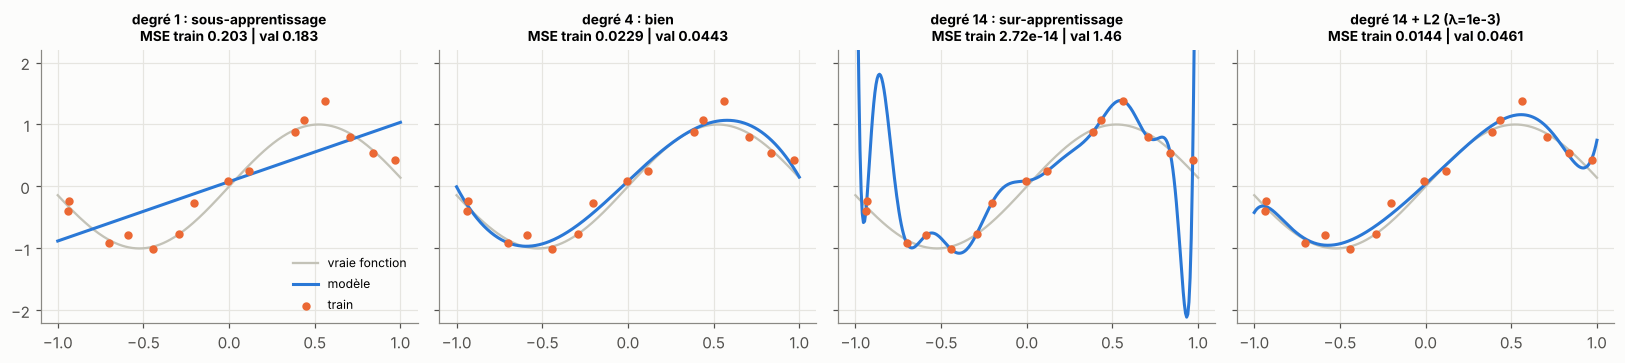

In [21]:
# Classic overfitting picture: polynomial regression with too much capacity
r = np.random.default_rng(3)
x_tr = np.clip(np.linspace(-1, 1, 15) + r.normal(0, 0.03, 15), -1, 1); y_tr = np.sin(3 * x_tr) + r.normal(0, 0.2, 15)
x_va = np.sort(r.uniform(-1, 1, 200)); y_va = np.sin(3 * x_va) + r.normal(0, 0.2, 200)
xs = np.linspace(-1, 1, 300)

def poly_fit(deg, lam=0.0):
    Phi_ = np.vander(x_tr, deg + 1)
    w = np.linalg.solve(Phi_.T @ Phi_ + lam * np.eye(deg + 1), Phi_.T @ y_tr)   # ridge closed form
    return lambda t: np.vander(t, deg + 1) @ w

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (deg, lam, title) in zip(axes, [(1, 0, "degré 1 : sous-apprentissage"), (4, 0, "degré 4 : bien"),
                                         (14, 0, "degré 14 : sur-apprentissage"), (14, 1e-3, "degré 14 + L2 (λ=1e-3)")]):
    fpoly = poly_fit(deg, lam)
    tr_err = np.mean((fpoly(x_tr) - y_tr) ** 2); va_err = np.mean((fpoly(x_va) - y_va) ** 2)
    ax.plot(xs, np.sin(3 * xs), color="#c3c2b7", lw=1.5, label="vraie fonction")
    ax.plot(xs, np.clip(fpoly(xs), -3, 3), color=PALETTE[0], label="modèle")
    ax.scatter(x_tr, y_tr, color=PALETTE[1], s=20, zorder=3, label="train")
    ax.set_title(f"{title}\nMSE train {tr_err:.3g} | val {va_err:.3g}", fontsize=9); ax.set_ylim(-2.2, 2.2)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Remarque l'écart **MSE train ≪ MSE validation** du degré 14 : c'est la signature du sur-apprentissage. La régularisation L2 le résorbe sans changer la capacité du modèle.

Même histoire avec notre MLP. Pour rendre le sur-apprentissage flagrant, on prend peu d'exemples et on **corrompt 20 % des étiquettes d'entraînement** (bruit d'annotation, très courant en NLP). Un réseau trop libre apprend ce bruit par cœur ; un réseau régularisé l'ignore.

L2=0.0: best val acc 91.2% at epoch 43 | final val acc 80.6%
L2=0.01: best val acc 94.2% at epoch 287 | final val acc 91.9%


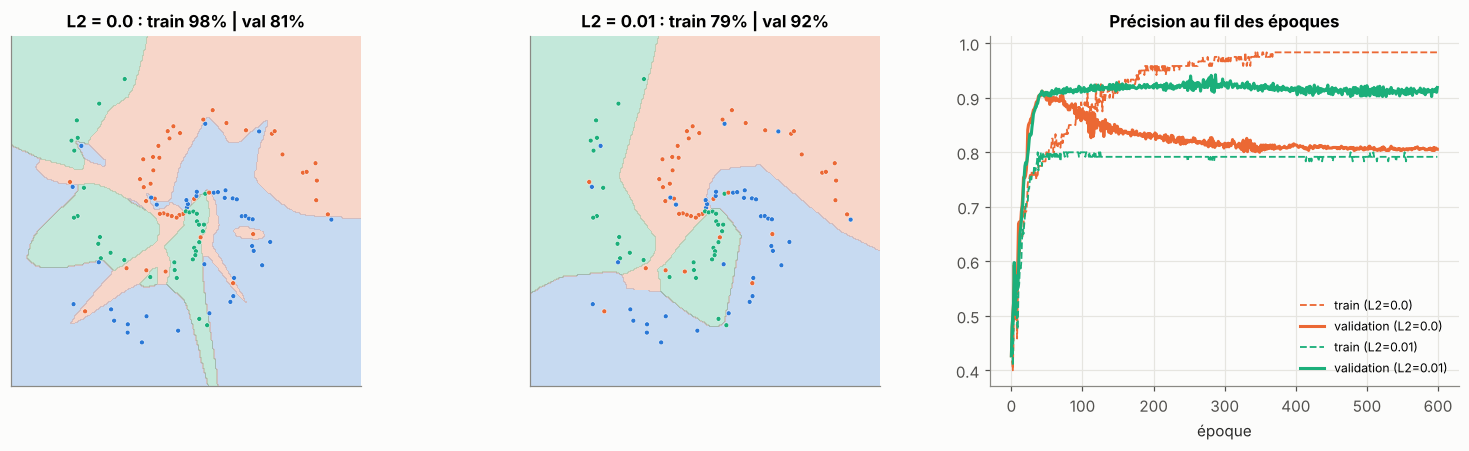

In [22]:
X_small, y_small = make_spirals(n_per_class=40, noise=0.2, seed=1)
X_val, y_val = make_spirals(n_per_class=300, noise=0.2, seed=2)       # clean validation set
r = np.random.default_rng(5)
flip = r.random(len(y_small)) < 0.2                                   # corrupt 20% of train labels
y_noisy = y_small.copy()
y_noisy[flip] = (y_noisy[flip] + r.integers(1, 3, flip.sum())) % 3

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, l2, c in [(axes[0], 0.0, PALETTE[1]), (axes[1], 1e-2, PALETTE[2])]:
    net_r = MLP([2, 256, 256, 3], seed=0)
    hst = train_numpy(net_r, X_small, y_noisy, Adam, lr=1e-2, epochs=600, batch_size=len(X_small),
                      l2=l2, X_val=X_val, y_val=y_val)
    plot_boundary(net_r, X_small, y_noisy, ax, f"L2 = {l2} : train {hst['acc'][-1]:.0%} | val {hst['val_acc'][-1]:.0%}")
    axes[2].plot(hst["acc"], color=c, ls="--", lw=1.2, label=f"train (L2={l2})")
    axes[2].plot(hst["val_acc"], color=c, label=f"validation (L2={l2})")
    best = int(np.argmax(hst["val_acc"]))
    print(f"L2={l2}: best val acc {max(hst['val_acc']):.1%} at epoch {best} | final val acc {hst['val_acc'][-1]:.1%}")
axes[2].set_title("Précision au fil des époques"); axes[2].set_xlabel("époque"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture** :
- Sans régularisation, la précision d'entraînement dépasse 95 % alors que 20 % des étiquettes sont fausses : le réseau a **mémorisé le bruit**. La frontière se tord autour des points mal étiquetés et la validation chute.
- La courbe de validation sans L2 atteint son maximum tôt puis se dégrade : c'est exactement ce que l'**early stopping** exploite (garder le checkpoint du meilleur score de validation).
- Avec L2, la précision d'entraînement plafonne autour de 80 %, ce qui est **le bon comportement** puisque 20 % des étiquettes sont fausses, et la validation est bien meilleure.

In [23]:
# Inverted dropout keeps the expectation unchanged
a = np.ones(100_000) * 2.0
p_drop = 0.3
mask = rng.random(a.shape) > p_drop
a_drop = a * mask / (1 - p_drop)
print(f"mean before: {a.mean():.3f} | fraction kept: {mask.mean():.3f} | mean after inverted dropout: {a_drop.mean():.3f}")

mean before: 2.000 | fraction kept: 0.700 | mean after inverted dropout: 2.001


## 11. La même chose en PyTorch

Tu connais maintenant chaque rouage. PyTorch automatise trois choses : les **tenseurs** sur GPU, l'**autograd** (notre classe `Value`, en version tableaux) et une bibliothèque de **couches, pertes et optimiseurs**. Le module 1 détaille PyTorch ; voici déjà le pont direct avec ce que tu as codé.

> ⚙️ Les cellules qui suivent nécessitent `torch` (`pip install torch`, ou Google Colab où il est préinstallé). Exécute d'abord les cellules précédentes : on réutilise `X_spiral`, `y_spiral`, `MLP`, etc.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
print(torch.__version__, "| CUDA available:", torch.cuda.is_available())

# 1) Autograd reproduces our hand-made example: L = (w*x + b - y)^2
x_t = torch.tensor(2.0)
w_t = torch.tensor(3.0, requires_grad=True)
b_t = torch.tensor(1.0, requires_grad=True)
L_t = (w_t * x_t + b_t - 5.0) ** 2
L_t.backward()
print("dL/dw =", w_t.grad.item(), "| dL/db =", b_t.grad.item())   # expected 8.0 and 4.0

In [ ]:
# 2) Check that our NumPy backprop matches PyTorch autograd on the same weights
np_net = MLP([2, 16, 16, 3], seed=1)
Xs, ys = X_spiral[:50], y_spiral[:50]
loss_np, gW_np, gb_np = np_net.loss_and_grads(Xs, ys)

torch_net = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 3)).double()
with torch.no_grad():
    for layer, W, b in zip([torch_net[0], torch_net[2], torch_net[4]], np_net.W, np_net.b):
        layer.weight.copy_(torch.from_numpy(W.T))   # nn.Linear stores W as (out, in)
        layer.bias.copy_(torch.from_numpy(b))

logits = torch_net(torch.from_numpy(Xs))
loss_t = F.cross_entropy(logits, torch.from_numpy(ys))   # expects raw logits + class indices
loss_t.backward()
print(f"loss numpy = {loss_np:.10f} | loss torch = {loss_t.item():.10f}")
for i, layer in enumerate([torch_net[0], torch_net[2], torch_net[4]]):
    diff = np.abs(layer.weight.grad.numpy().T - gW_np[i]).max()
    print(f"layer {i}: max |grad_torch - grad_numpy| = {diff:.2e}")

In [ ]:
# 3) Train the spiral MLP the PyTorch way
X_t = torch.tensor(X_spiral, dtype=torch.float32)
y_t = torch.tensor(y_spiral, dtype=torch.long)

model = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 3),                     # logits: NO softmax here
)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

losses = []
for epoch in range(200):
    perm = torch.randperm(len(X_t))
    for k in range(0, len(X_t), 64):
        idx = perm[k:k + 64]
        logits = model(X_t[idx])          # 1. forward
        loss = loss_fn(logits, y_t[idx])  # 2. loss
        optimizer.zero_grad()             # 3. reset accumulated grads
        loss.backward()                   # 4. backprop
        optimizer.step()                  # 5. update
    losses.append(loss.item())

model.eval()
with torch.no_grad():
    acc = (model(X_t).argmax(dim=1) == y_t).float().mean().item()
print(f"final train accuracy: {acc:.1%}")
plt.plot(losses); plt.title("PyTorch — perte du dernier mini-batch par époque"); plt.xlabel("époque"); plt.show()

Les cinq lignes numérotées de la boucle sont **la boucle d'entraînement universelle** : tu la retrouveras, à peine modifiée, pour entraîner un Transformer de plusieurs milliards de paramètres.

## 12. Récapitulatif

### 🧾 Antisèche

| Concept | À retenir |
|---|---|
| Neurone | $a=\phi(w^\top x+b)$ : hyperplan + non-linéarité |
| Couche dense | $Z = XW+b$, $X:(B,d)$, $W:(d,h)$ |
| Activation | ReLU/GELU dans les couches cachées ; sigmoïde/tanh saturent |
| Softmax | $e^{z_k}/\sum_j e^{z_j}$, soustraire le max ; température $z/T$ |
| Perte | NLL : MSE (gaussien), BCE (Bernoulli), CE (catégoriel) |
| Gradient clé | softmax + CE : $\partial\ell/\partial z = \hat p - y$ |
| Descente de gradient | $\theta \leftarrow \theta - \eta\nabla\mathcal L$, $\eta<2/\lambda_{\max}$ |
| Adam(W) | moments 1 et 2 + correction de biais (+ weight decay découplé) |
| Rétropropagation | règle de la chaîne en mode inverse ; $\partial W = X^\top\delta$, $\partial X = \delta W^\top$ |
| Initialisation | He : $\mathrm{Var}(w)=2/n_{in}$ (ReLU) ; Xavier : $2/(n_{in}+n_{out})$ |
| Régularisation | L2/weight decay, dropout (inversé), early stopping, plus de données |

### ⚠️ Pièges fréquents (et comment les détecter)

1. **Softmax avant `CrossEntropyLoss`** : PyTorch l'applique déjà. Symptôme : apprentissage très lent, perte bloquée.
2. **Oublier `optimizer.zero_grad()`** : les gradients s'accumulent d'un pas à l'autre. Symptôme : perte qui explose ou oscille.
3. **Oublier `model.eval()`** : dropout (et BatchNorm) restent actifs à l'évaluation. Symptôme : métriques de validation bruitées et sous-estimées.
4. **Perte initiale ≠ $\log K$** : initialisation ou étiquettes suspectes.
5. **Ne pas tester le sur-apprentissage d'un mini-batch** : un modèle correct doit atteindre une perte ≈ 0 sur 10 exemples. Sinon, il y a un bug (module 1).
6. **Learning rate** : si la perte diverge (NaN), divise $\eta$ par 3 à 10. Si elle descend trop lentement, multiplie-le. Balaye toujours en échelle logarithmique ($10^{-4}, 3\cdot10^{-4}, 10^{-3}, \dots$).

### 🏋️ Exercices

**Exercice 1 — Dérivée de la sigmoïde.** Montre que $\sigma'(z) = \sigma(z)(1-\sigma(z))$ et que son maximum vaut $1/4$.

<details><summary>Solution</summary>

$\sigma(z) = (1+e^{-z})^{-1}$, donc $\sigma'(z) = e^{-z}(1+e^{-z})^{-2} = \sigma(z)\cdot\frac{e^{-z}}{1+e^{-z}} = \sigma(z)(1-\sigma(z))$. Avec $s=\sigma(z)\in(0,1)$, $s(1-s)$ est maximal en $s=1/2$ (soit $z=0$) et vaut $1/4$.
</details>

**Exercice 2 — Ajoute `sigmoid` à la classe `Value`** et vérifie son gradient par différences finies.

<details><summary>Solution</summary>

```py
def sigmoid(self):
    s = 1 / (1 + np.exp(-self.data))
    out = Value(s, (self,), "sigmoid")
    def _backward():
        self.grad += s * (1 - s) * out.grad
    out._backward = _backward
    return out
Value.sigmoid = sigmoid
```
</details>

**Exercice 3 — Taux d'apprentissage critique.** Pour $\mathcal L(\theta) = \frac12\theta^\top A\theta$ avec $A=\mathrm{diag}(1, 20)$, quel est le plus grand $\eta$ qui converge ? Quel $\eta$ minimise le facteur de convergence le plus lent $\max_i |1-\eta\lambda_i|$ ?

<details><summary>Solution</summary>

Convergence ssi $|1-\eta\lambda_i|<1$ pour tout $i$ : $\eta < 2/20 = 0.1$. Le facteur $\max(|1-\eta|, |1-20\eta|)$ est minimisé quand les deux termes s'égalisent : $1-\eta = 20\eta - 1 \Rightarrow \eta^\star = 2/21 \approx 0.095$, avec un facteur $19/21 = (\kappa-1)/(\kappa+1)\approx 0.905$. Il faut donc environ 22 pas pour diviser l'erreur par 10 : un mauvais conditionnement ralentit tout.
</details>

**Exercice 4 — Dropout dans le MLP NumPy.** Ajoute un dropout inversé (paramètre `p`) après chaque ReLU dans `MLP.forward` en mode entraînement, et adapte la passe arrière. Indice : stocke le masque dans le cache, et multiplie `dA` par ce même masque divisé par $(1-p)$.

**Exercice 5 — Rétropropagation à la main.** Pour $Z = XW$ avec $X\in\mathbb R^{2\times 3}$ et $W \in\mathbb R^{3\times 1}$, et $L = \sum Z$, écris $\partial L/\partial W$ composante par composante et vérifie que c'est bien $X^\top \mathbf 1$.

<details><summary>Solution</summary>

$L = \sum_i \sum_j X_{ij}W_j$, donc $\partial L/\partial W_j = \sum_i X_{ij} = (X^\top\mathbf 1)_j$. On retrouve $X^\top\delta$ avec $\delta = \partial L/\partial Z = \mathbf 1$.
</details>

**Exercice 6 (défi).** Entraîne le MLP NumPy avec 6 couches cachées de 64 neurones en initialisant avec `init=0.01` puis `init="he"`. Trace les normes des gradients par couche au premier pas. Que constates-tu ? Relie au graphique de la section 9.

### 📚 Pour aller plus loin

- Goodfellow, Bengio, Courville — *Deep Learning*, chapitres 6 (réseaux), 7 (régularisation), 8 (optimisation). Gratuit sur deeplearningbook.org.
- A. Karpathy — *micrograd* et la vidéo « The spelled-out intro to neural networks and backpropagation ».
- 3Blue1Brown — série « Neural Networks » (intuition visuelle de la rétropropagation).
- Kingma & Ba (2015), *Adam* ; Loshchilov & Hutter (2019), *Decoupled Weight Decay Regularization* ; He et al. (2015), *Delving Deep into Rectifiers*.
- Zhang et al. — *Dive into Deep Learning* (d2l.ai), chapitres 3 à 5 et 12.

**➡️ Module suivant : PyTorch en pratique** (tenseurs, autograd, `nn.Module`, `Dataset`/`DataLoader`, boucle d'entraînement robuste et débogage).